# 02 — Alpha power over time

**Goal:** see the alpha rhythm switch on and off *as a curve over time*, instead of two averages.

Notebook 01 compared one number per minute. Here we glue the two minutes together (eyes open, then eyes closed),
cut the result into short windows and measure the alpha power in each window.
If the alpha rhythm is a reliable signal, the curve should be low for 60 s, then high for 60 s.

In [1]:
import matplotlib.pyplot as plt
import mne
import numpy as np
from mne.datasets import eegbci

mne.set_log_level("WARNING")

SUBJECT = 1
RUNS = {"eyes open": 1, "eyes closed": 2}
CHANNELS = ["O1", "Oz", "O2"]
ALPHA = (8, 12)   # Hz
WINDOW = 2        # seconds per measurement

## 1. Load and glue the two minutes

Same loading as notebook 01, then `concatenate_raws` puts the eyes-closed minute right after the eyes-open one.

In [2]:
raws = []
for condition, run in RUNS.items():
    [path] = eegbci.load_data(SUBJECT, [run], update_path=True)
    raw = mne.io.read_raw_edf(path, preload=True)
    eegbci.standardize(raw)
    raws.append(raw)

switch_time = raws[0].times[-1]  # the second where the eyes close
raw = mne.concatenate_raws(raws).pick(CHANNELS)

print(f"{len(raw.ch_names)} channels, {raw.times[-1]:.0f} s in total, eyes close at {switch_time:.0f} s")

3 channels, 122 s in total, eyes close at 61 s


## 2. Alpha power, window by window

Each window of `WINDOW` seconds becomes one point: the mean 8–12 Hz power over the chosen channels.

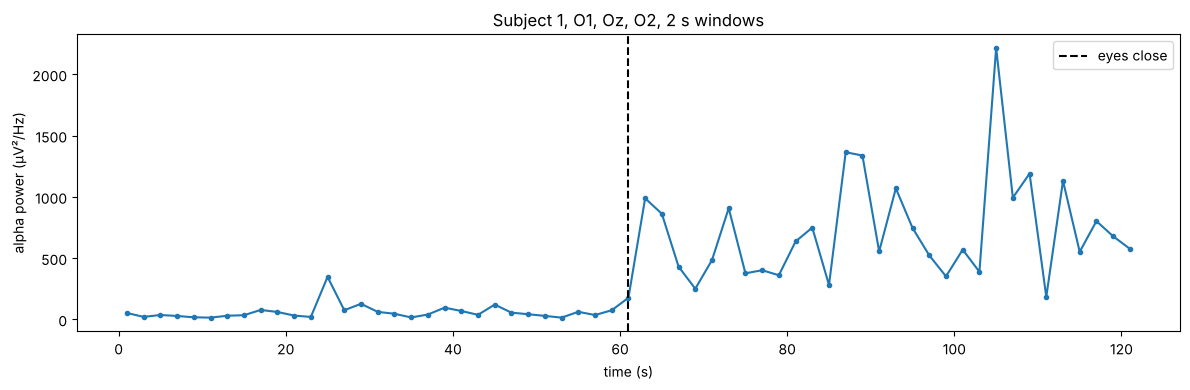

In [3]:
sfreq = raw.info["sfreq"]
data = raw.get_data() * 1e6  # µV
samples_per_window = int(WINDOW * sfreq)
n_windows = data.shape[1] // samples_per_window

times, alpha = [], []
for w in range(n_windows):
    chunk = data[:, w * samples_per_window:(w + 1) * samples_per_window]
    psd, freqs = mne.time_frequency.psd_array_welch(chunk, sfreq, fmin=1, fmax=40, n_per_seg=samples_per_window, verbose=False)
    in_alpha = (freqs >= ALPHA[0]) & (freqs <= ALPHA[1])
    alpha.append(psd[:, in_alpha].mean())
    times.append((w + 0.5) * WINDOW)
alpha = np.array(alpha)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(times, alpha, marker="o", ms=3)
ax.axvline(switch_time, color="k", ls="--", label="eyes close")
ax.set(xlabel="time (s)", ylabel=f"alpha power (µV²/Hz)", title=f"Subject {SUBJECT}, {', '.join(CHANNELS)}, {WINDOW} s windows")
ax.legend()
fig.tight_layout()

## 3. A threshold

A brain switch is just a line on this plot: above it we say "eyes closed", below it "eyes open".
We put the line halfway (in log scale) between the two medians, then count how often it is right.

median eyes open 41, median eyes closed 576, threshold 154
windows correctly classified: 98%


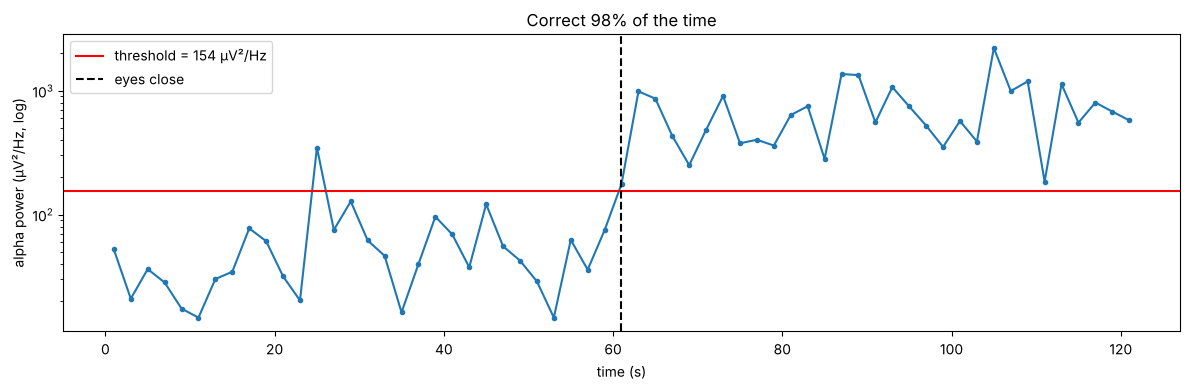

In [4]:
before = alpha[np.array(times) < switch_time]
after = alpha[np.array(times) >= switch_time]
threshold = np.sqrt(np.median(before) * np.median(after))  # geometric mean of the two medians

decided_closed = alpha > threshold
truth_closed = np.array(times) >= switch_time
accuracy = (decided_closed == truth_closed).mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.semilogy(times, alpha, marker="o", ms=3)
ax.axhline(threshold, color="r", label=f"threshold = {threshold:.0f} µV²/Hz")
ax.axvline(switch_time, color="k", ls="--", label="eyes close")
ax.set(xlabel="time (s)", ylabel="alpha power (µV²/Hz, log)", title=f"Correct {accuracy:.0%} of the time")
ax.legend()
fig.tight_layout()

print(f"median eyes open {np.median(before):.0f}, median eyes closed {np.median(after):.0f}, threshold {threshold:.0f}")
print(f"windows correctly classified: {accuracy:.0%}")

## What to remember

- The two averages of notebook 01 hide a curve: alpha power jumps the moment the eyes close and stays high.
- A threshold on that curve is a one-bit brain switch, and its error rate can be measured.
- `WINDOW` is a trade-off: short windows react fast but are noisy, long windows are smooth but slow.

**Try:** `WINDOW = 1`, then `WINDOW = 4`. Then `CHANNELS = ["C3", "C4"]`: is the switch still usable?